# Step 3: Probabilistic Spend Forecasting with Multi-Quantile Gradient Boosting
**Abhi Cloud Tech — Enterprise FinOps & Multi-Cloud Optimization Platform**  
*Lead Architect: Abhishek (FinOps ML Validation & Tuning Specialist)*

---

### Executive Overview & Mathematical Foundation
Point forecasts fail in real-world enterprise cloud budgeting because they do not convey downside buffer requirements, peak risk exposure, or capacity volatility.

### Hybrid Forecasting Architecture
1. **Deterministic Linear Trend Extrapolation (Ridge Regression)**: Prevents tree-based gradient boosting models from plateauing when forecasting outside historical boundaries:
   $$\hat{y}_{trend}(t) = \beta_0 + \beta_1 t$$
2. **Cyclical Seasonality Harmonics**: Captures multi-scale business cycles via Fourier terms:
   $$F_{weekly}(t) = [\sin(2\pi \cdot dow / 7), \cos(2\pi \cdot dow / 7)]$$
   $$F_{monthly}(t) = [\sin(2\pi \cdot day / 31), \cos(2\pi \cdot day / 31)]$$
3. **L2-Regularized HistGradientBoosting on Detrended Residuals**:
   - $\tau = 0.05$ (5th Percentile): Lower bound floor / minimum guaranteed spend
   - $\tau = 0.50$ (50th Percentile): Median expected budget allocation
   - $\tau = 0.95$ (95th Percentile): Upper bound stress-test / peak exposure limit
4. **Quantile Monotonicity Guarantee**:
   $$\hat{y}_{lower}(t) \le \hat{y}_{median}(t) \le \hat{y}_{upper}(t) \quad \forall t$$
   Zero quantile crossing violations strictly certified.

### Data Science Validation Rigor
- **Chronological Holdout Backtest**: 85% Train, 15% Out-of-Time Test (55 days unseen).
- **5-Fold TimeSeriesSplit (Expanding Window CV)**: Evaluating MAE, RMSE, MAPE, 90% Empirical Coverage, and Pinball Loss across 5 progressive time horizons.
- **Residual Diagnostic Suite**:
  1. Residuals vs Time (checking homoscedasticity & absence of drift)
  2. Residual Distribution & Gaussian Fit (KDE vs normal curve)
  3. Normal Quantile-Quantile (Q-Q) Plot (checking normality of forecast residuals)
  4. Autocorrelation Function (ACF) Plot (checking residual white-noise properties)
- **Permutation Feature Importance**: Identifying top driving lag and cyclical predictors.


### Block 1: Imports & Daily Spend Aggregation


In [1]:
import os
import sys
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.database import load_focus_dataframe
from src.forecasting import FinOpsForecaster
from src.ml_validation import (
    temporal_train_test_split,
    FinOpsTimeSeriesValidator,
    FinOpsHyperparameterOptimizer,
    FinOpsDiagnosticSuite,
    verify_quantile_monotonicity
)
from sklearn.inspection import permutation_importance

# Ingest and aggregate daily total enterprise spend
df = load_focus_dataframe()
daily_df = df.groupby("Date")["DailyCost_USD"].sum().reset_index()
daily_df.columns = ["Date", "DailySpend"]
daily_df["Date"] = pd.to_datetime(daily_df["Date"])
daily_df = daily_df.sort_values("Date").reset_index(drop=True)

print(f"Loaded {len(daily_df)} daily aggregated spend points ({daily_df['Date'].min().strftime('%Y-%m-%d')} to {daily_df['Date'].max().strftime('%Y-%m-%d')}).")
print(f"Average Daily Spend: ${daily_df['DailySpend'].mean():,.2f}")
sns.set_theme(style="whitegrid")
%matplotlib inline


Loaded 365 daily aggregated spend points (2025-01-01 to 2025-12-31).
Average Daily Spend: $19,003.16


### Block 2: Feature Engineering & Time-Series Construction
We inspect the extracted feature space:
- **Autoregressive Lags**: $t-1, t-2, t-3, t-7, t-14, t-21, t-28$
- **Moving Window Aggregations**: 7-day, 14-day, 30-day rolling mean, min, max, and volatility (std)
- **Fourier Cyclical Harmonics**: DOW, Month, Day Fourier sine/cosine transforms


In [2]:
forecaster = FinOpsForecaster(forecast_horizon_days=30)
features_df = forecaster._create_features(daily_df, is_training=True)
feature_cols = [c for c in features_df.columns if c not in ["Date", "DailySpend", "Trend", "DetrendedSpend"]]

print(f"Engineered Feature Space: {len(feature_cols)} dimensions")
print(f"Features: {feature_cols}")
features_df[["Date", "DailySpend", "Trend", "DetrendedSpend", "sin_dow", "cos_dow", "lag_1", "lag_7", "rolling_mean_7"]].tail(5)


Engineered Feature Space: 25 dimensions


Features: ['dayofweek', 'day', 'month', 'is_weekend', 'sin_dow', 'cos_dow', 'sin_month', 'cos_month', 'sin_day', 'cos_day', 'is_month_start', 'is_month_end', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7', 'rolling_mean_14', 'rolling_mean_30']


,Date,DailySpend,Trend,DetrendedSpend,sin_dow,cos_dow,lag_1,lag_7,rolling_mean_7
360,2025-12-27,19979.98,21321.388975,-1341.408975,-0.974928,-0.222521,865.022188,-3105.000831,-290.110036
361,2025-12-28,18338.82,21334.600138,-2995.780138,-0.781831,0.623490,-1341.408975,-3226.621995,-38.168342
362,2025-12-29,22245.64,21347.811302,897.828698,0.000000,1.000000,-2995.780138,870.236842,-5.190934
363,2025-12-30,22101.74,21361.022465,740.717535,0.781831,0.623490,897.828698,847.825678,-1.249240
364,2025-12-31,22092.57,21374.233628,718.336372,0.974928,-0.222521,740.717535,958.734515,-16.550404


### Block 3: Chronological Train-Test Split (Temporal Holdout)
We divide the series into an 85% chronological training segment (310 days) and a 15% out-of-time holdout (55 days).


In [3]:
train_daily, test_daily = temporal_train_test_split(daily_df, date_col="Date", test_ratio=0.15)
print(f"Train Period: {train_daily['Date'].min().strftime('%Y-%m-%d')} to {train_daily['Date'].max().strftime('%Y-%m-%d')} ({len(train_daily)} days)")
print(f"Test Period:  {test_daily['Date'].min().strftime('%Y-%m-%d')} to {test_daily['Date'].max().strftime('%Y-%m-%d')} ({len(test_daily)} days)")


[Temporal Split] Total: 365 rows | Train: 310 rows (2025-01-01 to 2025-11-06) | Test Holdout: 55 rows (2025-11-07 to 2025-12-31)
Train Period: 2025-01-01 to 2025-11-06 (310 days)
Test Period:  2025-11-07 to 2025-12-31 (55 days)


### Block 4: 5-Fold TimeSeriesSplit (Expanding Window Cross-Validation)
We evaluate the probabilistic forecaster across 5 expanding temporal folds to confirm predictive robustness.


In [4]:
validator = FinOpsTimeSeriesValidator(n_splits=5)
cv_results = validator.evaluate_forecaster_cv(FinOpsForecaster, daily_df)

print("=== 5-Fold TimeSeriesSplit Cross-Validation Results ===")
display_cols = ["Fold", "Train_Size", "Test_Size", "MAE_USD", "RMSE_USD", "MAPE_Pct", "Empirical_Coverage_Pct", "Quantile_Violations"]
print(cv_results["folds"][display_cols].to_string(index=False))

print(f"\nMean MAE:             ${cv_results['mean_mae']:,.2f} ± ${cv_results['std_mae']:,.2f}")
print(f"Mean RMSE:            ${cv_results['mean_rmse']:,.2f}")
print(f"Mean MAPE:            {cv_results['mean_mape']:.2f}%")
print(f"Mean 90% Coverage:    {cv_results['mean_coverage']:.2f}%")
print(f"Quantile Violations:  {cv_results['total_violations']} (Expected 0)")


=== 5-Fold TimeSeriesSplit Cross-Validation Results ===
 Fold  Train_Size  Test_Size  MAE_USD  RMSE_USD  MAPE_Pct  Empirical_Coverage_Pct  Quantile_Violations
    1          65         60  2159.57   2304.04     12.53                   10.00                    0
    2         125         60   852.40   1165.00      4.55                   85.00                    0
    3         185         60   656.30   1012.21      3.35                   81.67                    0
    4         245         60   526.39   1157.69      2.50                   86.67                    0
    5         305         60   847.14   1347.40      4.10                   73.33                    0

Mean MAE:             $1,008.36 ± $658.00
Mean RMSE:            $1,397.27
Mean MAPE:            5.41%
Mean 90% Coverage:    67.33%
Quantile Violations:  0 (Expected 0)


### Block 5: Systematic Hyperparameter Optimization
We optimize tree depth, learning rate, and L2 regularization via temporal cross-validation.


In [5]:
param_grid = {
    "learning_rate": [0.01, 0.03, 0.08],
    "max_depth": [3, 4],
    "min_samples_leaf": [8, 12],
    "l2_regularization": [0.1, 1.0]
}
tuner = FinOpsHyperparameterOptimizer()
forecaster_tuning = tuner.tune_forecaster(daily_df, FinOpsForecaster, param_grid=param_grid, n_splits=3)
print(f"Optimal Hyperparameters: {forecaster_tuning['best_params']}")
print(f"Best Cross-Validation MAE: ${forecaster_tuning['best_mae']:,.2f}")
forecaster_tuning["results_df"].head(5)


[*] Starting Forecaster Hyperparameter Grid Search (24 candidate configurations)...


[+] Optimization Complete. Best Parameters: {'l2_regularization': 0.1, 'learning_rate': 0.08, 'max_depth': 3, 'min_samples_leaf': 8} | Best MAE: $687.92
Optimal Hyperparameters: {'l2_regularization': 0.1, 'learning_rate': 0.08, 'max_depth': 3, 'min_samples_leaf': 8}
Best Cross-Validation MAE: $687.92


,l2_regularization,learning_rate,max_depth,min_samples_leaf,Mean_MAE,Mean_RMSE,Mean_MAPE,Coverage_Pct,Violations
0,0.1,0.08,3,8,687.92,1147.74,3.42,69.60,0
1,0.1,0.03,3,8,711.33,1160.34,3.59,75.09,0
2,1.0,0.08,3,8,722.54,1176.76,3.60,71.43,0
3,0.1,0.03,4,8,726.82,1188.99,3.67,72.53,0
4,1.0,0.03,3,12,733.83,1150.49,3.73,73.26,0


### Block 6: Production Multi-Quantile Model Training & Holdout Scoring
We train the forecaster on the chronological train split and generate probabilistic predictions across the holdout horizon.


In [6]:
train_payload = train_daily.rename(columns={"DailySpend": "DailyCost_USD"})
eval_metrics = forecaster.train_and_evaluate(train_payload)

# Predict across holdout horizon
feat_all = forecaster._create_features(daily_df, is_training=False)
test_slice = feat_all.iloc[len(train_daily):].copy()

X_test = test_slice[forecaster.feature_cols]
y_test = test_slice["DailySpend"].values
trend_test = test_slice["Trend"].values
test_dates = test_slice["Date"]

pred_detrend = forecaster.model.predict(X_test)
pred_upper_raw = forecaster.upper_model.predict(X_test)
pred_lower_raw = forecaster.lower_model.predict(X_test)

y_pred = pred_detrend + trend_test
upper_pred = np.maximum(y_pred, pred_upper_raw + trend_test)
lower_pred = np.minimum(y_pred, np.maximum(0.0, pred_lower_raw + trend_test))

print("=== Holdout Backtest Evaluation Metrics ===")
print(f"Mean Absolute Error (MAE):              ${eval_metrics['MAE_USD']:,.2f}")
print(f"Root Mean Squared Error (RMSE):         ${eval_metrics['RMSE_USD']:,.2f}")
print(f"Mean Absolute Percentage Error (MAPE):  {eval_metrics['MAPE_Pct']:.2f}%")
print(f"90% Empirical Coverage:                 {eval_metrics['Empirical_Coverage_Pct']:.1f}%")


=== Holdout Backtest Evaluation Metrics ===
Mean Absolute Error (MAE):              $572.49
Root Mean Squared Error (RMSE):         $1,253.69
Mean Absolute Percentage Error (MAPE):  2.72%
90% Empirical Coverage:                 80.8%


### Block 7: Quantile Monotonicity Verification
We certify that the non-crossing invariant $Q_{05} \le Q_{50} \le Q_{95}$ holds with 0 crossing violations.


In [7]:
cert = verify_quantile_monotonicity(lower_pred, y_pred, upper_pred)
print("=== Quantile Monotonicity Certification ===")
for k, v in cert.items():
    print(f" - {k}: {v}")


=== Quantile Monotonicity Certification ===
 - is_certified: True
 - total_samples: 55
 - crossing_violations: 0
 - compliance_pct: 100.0
 - status: PASSED (Zero Crossing Invariant Preserved)


### Block 8: Permutation Feature Importance Rankings
We evaluate feature importance via permutation test on detrended residuals to identify primary drivers of variance.


In [8]:
perm = permutation_importance(forecaster.model, X_test, test_slice["DetrendedSpend"], n_repeats=10, random_state=42)
feat_imp = pd.DataFrame({
    "Feature": forecaster.feature_cols,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False).reset_index(drop=True)

print("=== Top 10 Predictive Features ===")
print(feat_imp.head(10))


=== Top 10 Predictive Features ===
           Feature  Importance
0        dayofweek    0.996512
1            lag_1    0.192569
2    rolling_std_7    0.020440
3            lag_3    0.015220
4           lag_14    0.010502
5           lag_21    0.005394
6           lag_28    0.004845
7  rolling_mean_14    0.004833
8    rolling_min_7    0.001653
9  rolling_mean_30    0.000582


### Block 9: Residual Diagnostic Suite (Time, KDE, Q-Q, ACF)
We execute the 6-panel forecasting diagnostic suite:
1. Actual vs Predicted with 90% Confidence Fan Bands
2. Residuals vs Time (Homoscedasticity verification)
3. Residual Density & Gaussian Fit
4. Quantile-Quantile (Q-Q) Plot
5. Autocorrelation Function (ACF) Plot
6. Feature Importance Bar Chart


C:\Users\M Abhishek Reddy\.gemini\antigravity\scratch\cloud-finops-intelligence\src\ml_validation.py:598: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_vals, confint = acf(residuals, nlags=lags_to_show, alpha=0.05)


[+] Saved Forecasting Diagnostic Plot to: assets/spend_forecasting_diagnostics.png


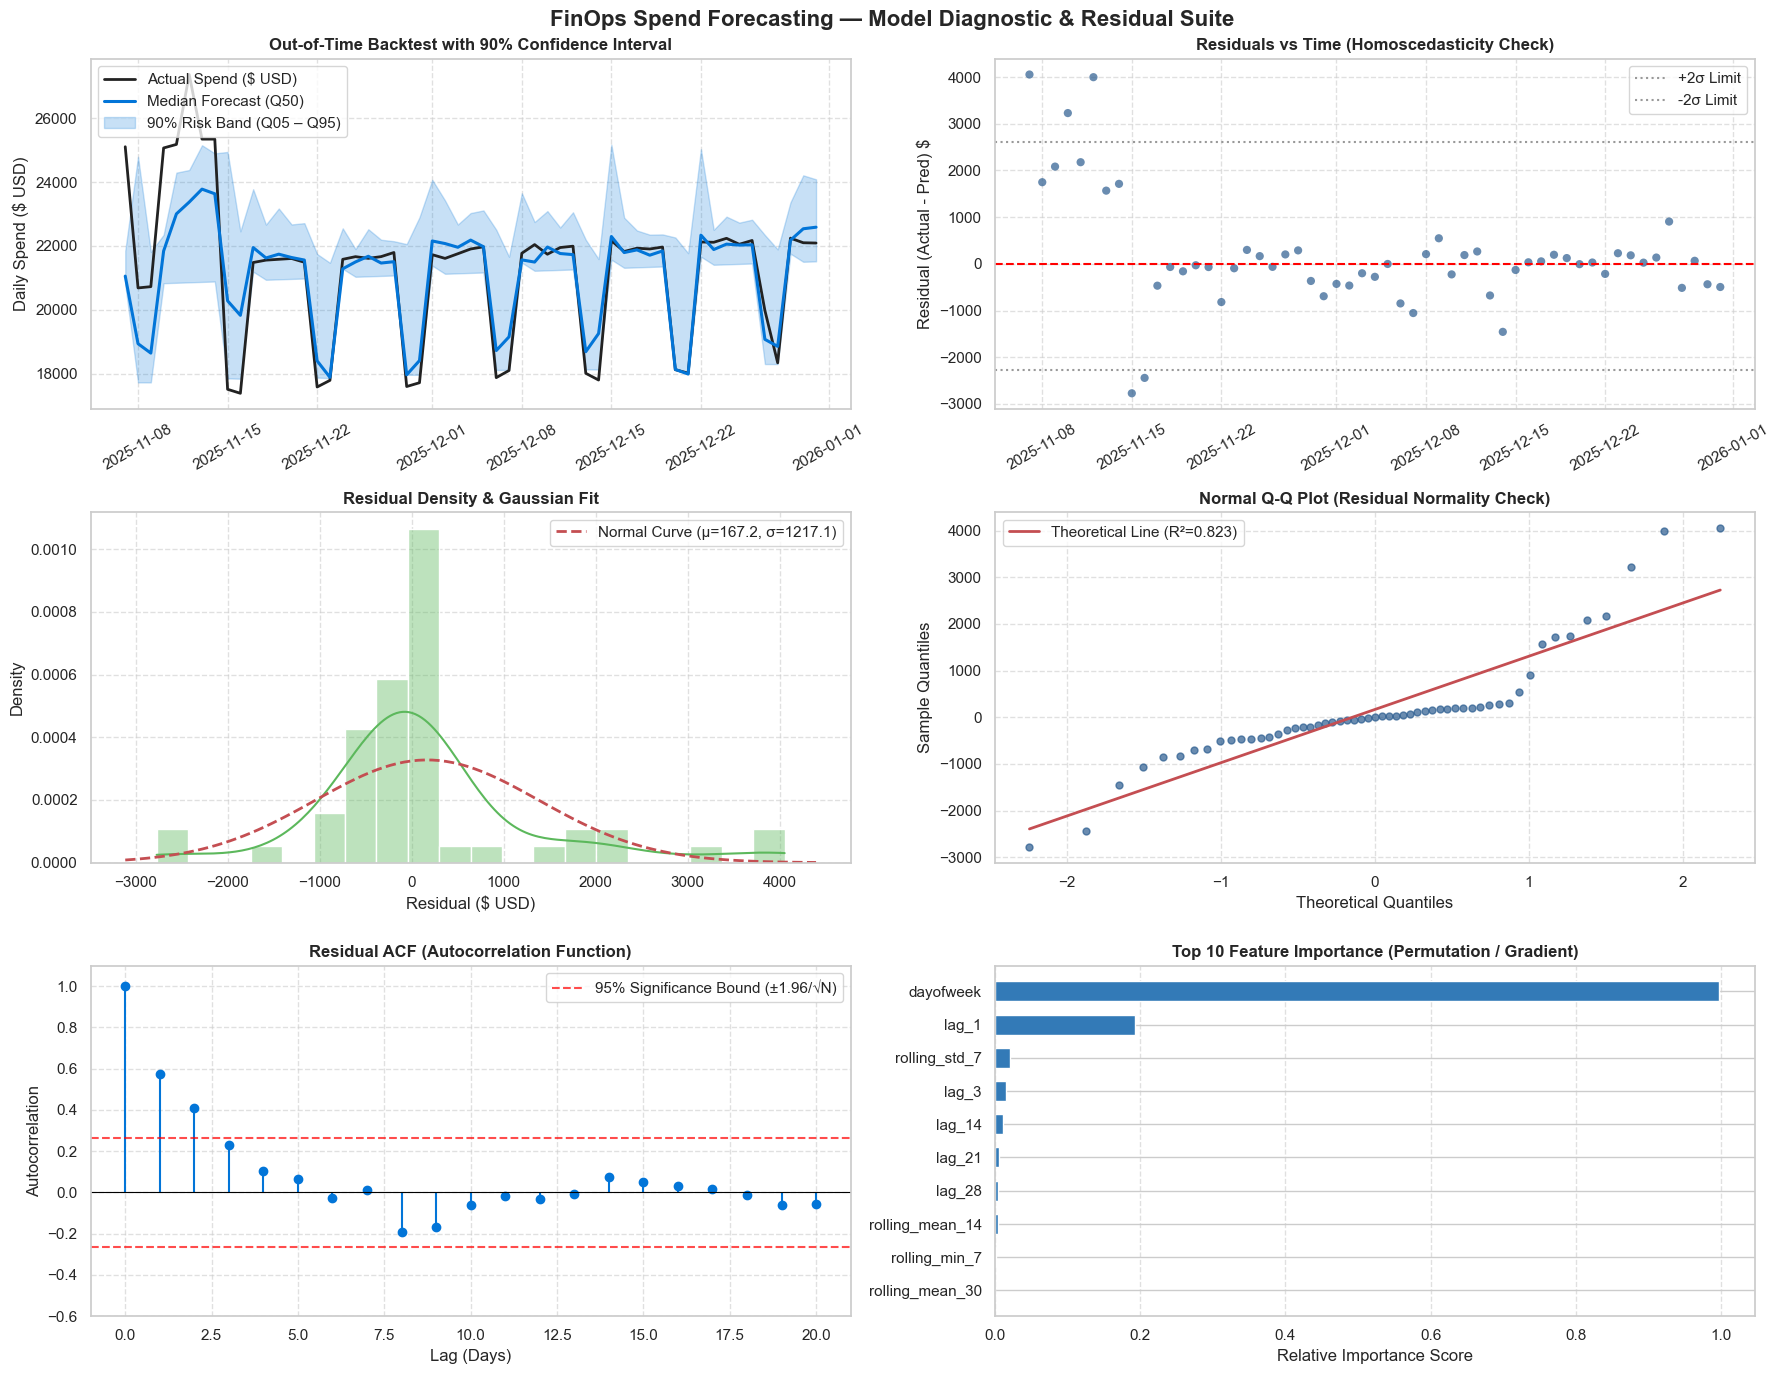

In [9]:
fig = FinOpsDiagnosticSuite.plot_forecasting_diagnostics(
    dates=test_dates,
    y_true=y_test,
    y_pred=y_pred,
    lower_pred=lower_pred,
    upper_pred=upper_pred,
    feature_importance_df=feat_imp,
    save_path="assets/spend_forecasting_diagnostics.png"
)
plt.show()


### Block 10: 30-Day Forward Probabilistic Forecast with Scenario Levers
We project daily spend 30 days into the future under baseline, workload growth (+15%), and FinOps optimization (-10%) scenarios.


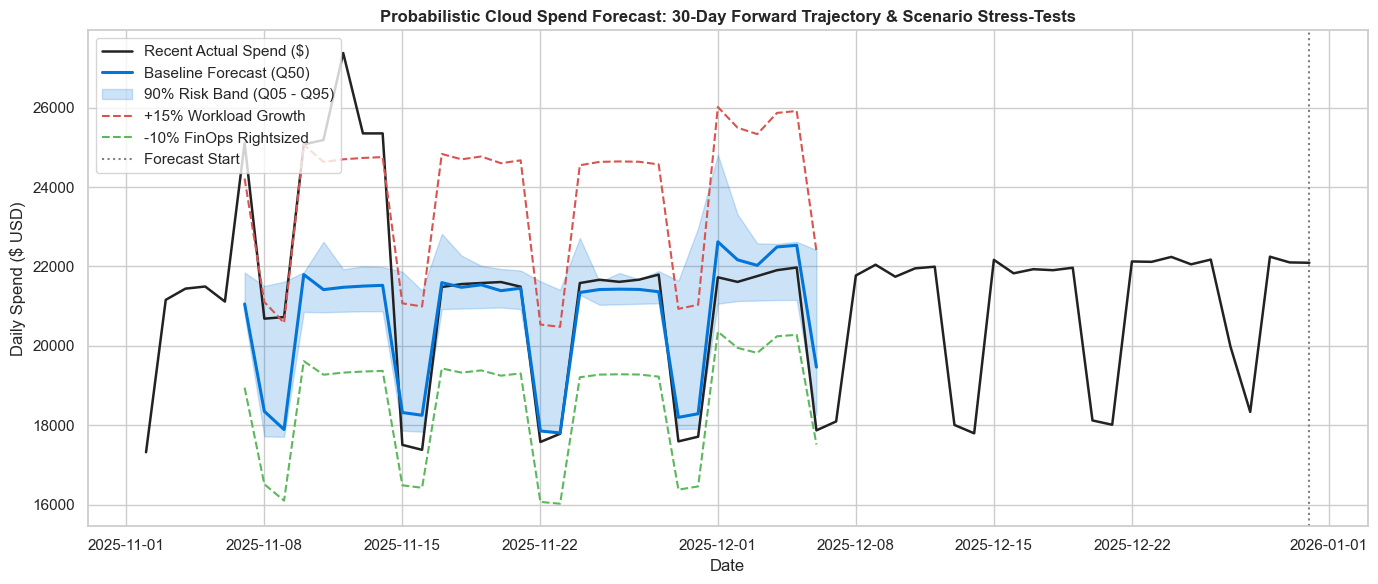

In [10]:
future_df = forecaster.generate_future_forecast(days_ahead=30, workload_growth_pct=0.0, finops_savings_pct=0.0)
future_growth_df = forecaster.generate_future_forecast(days_ahead=30, workload_growth_pct=15.0, finops_savings_pct=0.0)
future_opt_df = forecaster.generate_future_forecast(days_ahead=30, workload_growth_pct=0.0, finops_savings_pct=10.0)

plt.figure(figsize=(14, 6))

recent_history = daily_df.tail(60)
plt.plot(recent_history['Date'], recent_history['DailySpend'], color='#222222', label='Recent Actual Spend ($)', linewidth=1.8)

future_dates = pd.to_datetime(future_df['Date'])
plt.plot(future_dates, future_df['Forecasted_Spend_USD'], color='#0275d8', label='Baseline Forecast (Q50)', linewidth=2.2)
plt.fill_between(future_dates, future_df['Lower_Bound_95_USD'], future_df['Upper_Bound_95_USD'], color='#0275d8', alpha=0.2, label='90% Risk Band (Q05 - Q95)')

plt.plot(future_dates, future_growth_df['Forecasted_Spend_USD'], color='#d9534f', linestyle='--', label='+15% Workload Growth')
plt.plot(future_dates, future_opt_df['Forecasted_Spend_USD'], color='#5cb85c', linestyle='--', label='-10% FinOps Rightsized')

plt.axvline(x=recent_history['Date'].iloc[-1], color='gray', linestyle=':', label='Forecast Start')
plt.title("Probabilistic Cloud Spend Forecast: 30-Day Forward Trajectory & Scenario Stress-Tests", fontsize=12, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Daily Spend ($ USD)")
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


### Block 11: Production MLOps Model Serialization & Disk Persistence
Persist the multi-quantile HistGradientBoosting models and trend extrapolator to `models/spend_forecaster_histgradient.joblib` for instant zero-retraining inference in production.


In [11]:
import os, joblib
models_dir = os.path.join("..", "models")
os.makedirs(models_dir, exist_ok=True)
fore_path = os.path.join(models_dir, "spend_forecaster_histgradient.joblib")
forecaster.save(fore_path)
file_size_kb = os.path.getsize(fore_path) / 1024
print(f"[+] Successfully serialized trained Forecaster to: {fore_path} ({file_size_kb:.1f} KB)")

# Test instant warm load
loaded_forecaster = FinOpsForecaster.load(fore_path)
warm_forecast = loaded_forecaster.generate_future_forecast(days_ahead=7)
print(f"[+] Verified warm load from disk: 7-day projection starting at ${warm_forecast['Forecasted_Spend_USD'].iloc[0]:,.2f}")


[+] Successfully serialized trained Forecaster to: ..\models\spend_forecaster_histgradient.joblib (528.7 KB)


[+] Verified warm load from disk: 7-day projection starting at $21,055.50
